# Exploratory analysis

A first look at the cleaned warehouse (`clean.*`) before any formal analysis: what the data contains, how it is distributed, and which questions it raises. Each question raised here is answered properly in `sql/` or `notebooks/statistical_analysis.ipynb`.

Requires the pipeline to have run (`python src/pipeline.py`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import db

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (9, 3.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b3"
conn = db.connect()
sql = lambda q: db.query(conn, q)

## 1. What is in the data?

In [2]:
sql('''
SELECT 'orders' AS table_name, count(*) AS rows, min(order_date)::text AS first, max(order_date)::text AS last FROM clean.orders
UNION ALL SELECT 'order lines', count(*), NULL, NULL FROM clean.order_items
UNION ALL SELECT 'customers', count(*), min(signup_date)::text, max(signup_date)::text FROM clean.customers
UNION ALL SELECT 'products', count(*), NULL, NULL FROM clean.products
UNION ALL SELECT 'stock snapshots', count(*), min(snapshot_date)::text, max(snapshot_date)::text FROM clean.inventory_daily''')

,table_name,rows,first,last
0,products,371,NaN,NaN
1,customers,92000,2024-01-01,2025-12-31
2,orders,144790,2024-01-01,2025-12-31
3,order lines,338182,NaN,NaN
4,stock snapshots,256557,2024-01-01,2025-12-31


In [3]:
sql('''SELECT status, count(*) AS orders, round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct
FROM clean.orders GROUP BY 1 ORDER BY 2 DESC''')

,status,orders,pct
0,completed,131531,90.8
1,cancelled,7830,5.4
2,refunded,5429,3.7


## 2. How are order values distributed?

Order values are right-skewed: most orders are small, a few are very large. That matters for every average reported later (mean vs median, and the bulk B2B orders).

count   136,960.00
mean        161.35
std         165.41
min          -0.02
25%          63.99
50%         123.98
75%         214.19
95%         425.95
99%         676.66
max      11,029.34


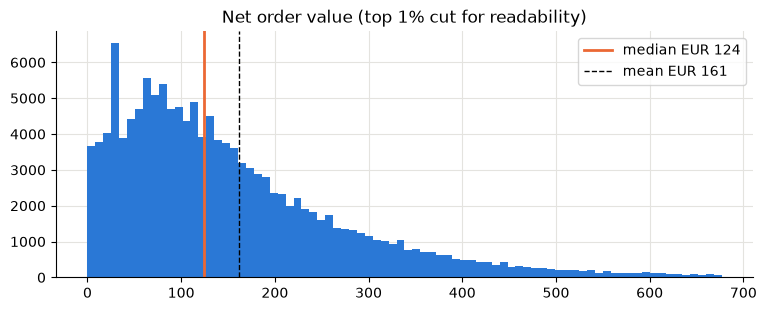

In [4]:
o = sql("SELECT net_revenue::float AS v, units, has_bulk FROM clean.order_summary WHERE is_fulfilled")
print(o["v"].describe(percentiles=[.25, .5, .75, .95, .99]).round(2).to_string())
fig, ax = plt.subplots()
ax.hist(o.loc[o["v"] < o["v"].quantile(.99), "v"], bins=80, color=BLUE)
ax.axvline(o["v"].median(), color=ORANGE, lw=2, label=f"median EUR {o['v'].median():.0f}")
ax.axvline(o["v"].mean(), color="black", lw=1, ls="--", label=f"mean EUR {o['v'].mean():.0f}")
ax.set_title("Net order value (top 1% cut for readability)"); ax.legend(); plt.show()

## 3. Trend and seasonality

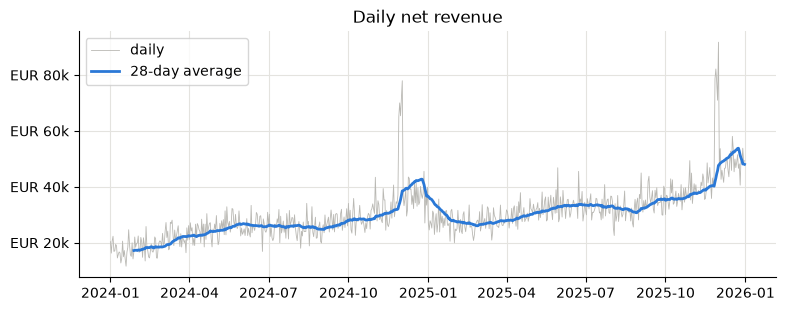

In [5]:
d = sql('''SELECT order_date::date AS day, sum(net_revenue)::float AS rev FROM clean.order_summary GROUP BY 1 ORDER BY 1''')
d["day"] = pd.to_datetime(d["day"])
fig, ax = plt.subplots()
ax.plot(d["day"], d["rev"], color=GREY, lw=0.6, label="daily")
ax.plot(d["day"], d["rev"].rolling(28).mean(), color=BLUE, lw=2, label="28-day average")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"EUR {x/1e3:.0f}k"))
ax.set_title("Daily net revenue"); ax.legend(); plt.show()

In [6]:
w = sql('''SELECT to_char(order_date, 'ID Dy') AS weekday, round(avg(rev)) AS avg_revenue FROM
  (SELECT order_date, sum(net_revenue) AS rev FROM clean.order_summary GROUP BY 1) x GROUP BY 1 ORDER BY 1''')
w

,weekday,avg_revenue
0,1 Mon,31878
1,2 Tue,30819
2,3 Wed,30243
3,4 Thu,30456
4,5 Fri,30455
5,6 Sat,28333
6,7 Sun,29409


**Questions raised:** growth looks steady with a strong November-December peak. Is the growth underlying or just the peak? (answered in `sql/03_revenue_trends.sql`, Q03.5). Black Friday days are clear outliers: the anomaly detection must not treat them as surprises.

## 4. Products: revenue vs profit

In [7]:
p = sql('''SELECT product_name, category, sum(net_revenue)::float AS revenue, sum(gross_profit)::float AS profit
FROM clean.sales_lines WHERE order_date >= '2025-01-01' GROUP BY 1, 2''')
p["margin"] = p["profit"] / p["revenue"]
p["share"] = p["revenue"].sort_values(ascending=False).cumsum() / p["revenue"].sum()
print(f"{(p['share'] <= 0.8).mean():.0%} of products produce 80% of revenue")
print("Spearman correlation of revenue rank and profit rank:",
      round(p['revenue'].rank().corr(p['profit'].rank(), method='spearman'), 3))
p.sort_values("revenue", ascending=False).head(10)

20% of products produce 80% of revenue


Spearman correlation of revenue rank and profit rank: 0.971


,product_name,category,revenue,profit,margin,share
136,Laptop Sleeve 2 T125,Bags & Travel,"2,235,827.53","1,019,103.18",0.46,0.18
351,Wireless Mouse Mini T125,Computer Accessories,"750,360.24","297,878.68",0.40,0.24
161,Mechanical Keyboard Pro Q322,Computer Accessories,"631,186.78","151,626.13",0.24,0.29
86,Earbuds Max P729,Audio,"598,894.48","285,705.03",0.48,0.34
334,Webcam Max Y914,Computer Accessories,"452,866.10","236,265.62",0.52,0.37
143,Laptop Stand 2 N643,Computer Accessories,"271,017.74","124,149.01",0.46,0.40
144,Laptop Stand Lite B655,Computer Accessories,"262,383.04","97,626.70",0.37,0.42
244,Security Camera Lite G544,Smart Home,"252,793.21","82,876.75",0.33,0.44
206,Phone Charger Plus T125,Phone Accessories,"244,672.79","114,144.56",0.47,0.46
339,Wireless Headphones A100,Audio,"175,623.95","70,632.36",0.40,0.47


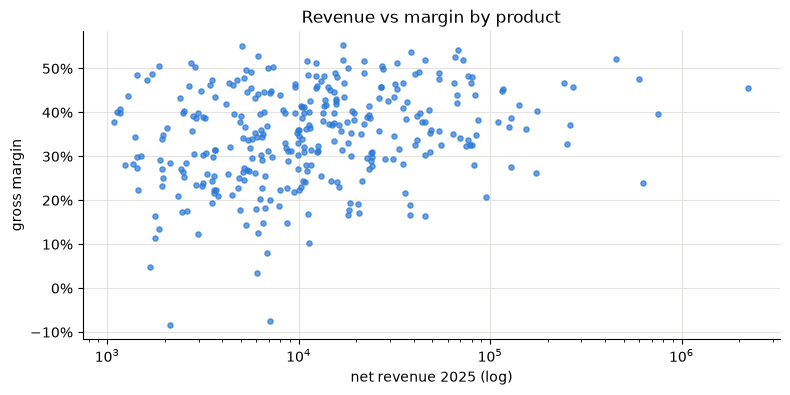

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
q = p[p["revenue"] > 1000]
ax.scatter(q["revenue"], q["margin"], s=14, color=BLUE, alpha=.7)
ax.set_xscale("log"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("net revenue 2025 (log)"); ax.set_ylabel("gross margin"); ax.set_title("Revenue vs margin by product")
plt.show()

**Question raised:** revenue rank and profit rank are highly correlated overall, but some high-revenue products have low margins. Which, and why? (answered in `sql/12_profitability.sql`, Q12.4 - Q12.6)

## 5. Customers

In [9]:
c = sql('''SELECT orders, count(*) AS customers FROM reporting.dim_customer WHERE orders IS NOT NULL
GROUP BY 1 ORDER BY 1''')
c["pct"] = 100 * c["customers"] / c["customers"].sum()
c.head(8)

,orders,customers,pct
0,1,57557,65.66
1,2,19319,22.04
2,3,6888,7.86
3,4,2382,2.72
4,5,958,1.09
5,6,367,0.42
6,7,119,0.14
7,8,39,0.04


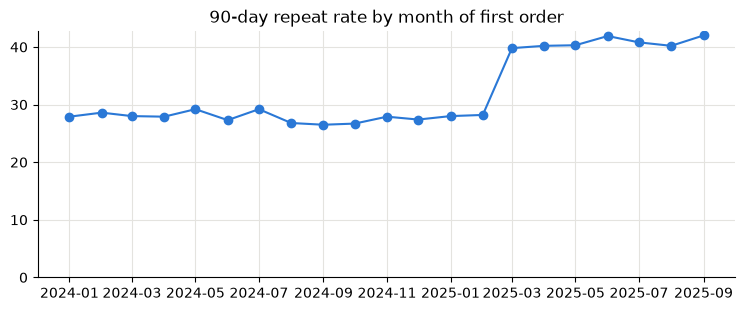

In [10]:
# lead() finds each customer's next order in one pass (a correlated EXISTS takes minutes here)
r = sql('''WITH o AS (SELECT customer_id, order_date,
    row_number() OVER (PARTITION BY customer_id ORDER BY order_date, order_id) AS n,
    lead(order_date) OVER (PARTITION BY customer_id ORDER BY order_date, order_id) AS next_order
  FROM clean.orders WHERE status <> 'cancelled' AND customer_id IS NOT NULL)
SELECT date_trunc('month', order_date)::date AS cohort,
       round(100.0 * avg(COALESCE(next_order - order_date <= 90, false)::int), 1) AS repeat_90d_pct
FROM o WHERE n = 1 AND order_date <= '2025-09-30' GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots()
ax.plot(pd.to_datetime(r["cohort"]), r["repeat_90d_pct"], marker="o", color=BLUE)
ax.set_title("90-day repeat rate by month of first order"); ax.set_ylim(0); plt.show()

**Question raised:** a step change in March 2025. The loyalty programme launched then, but a courier change followed in May. Which one caused it? (answered in `sql/07_cohort_retention.sql`, Q07.3 - Q07.5, and tested in `reports/statistical_tests.md`)

## 6. Discounts

About one order in five uses a discount code. The natural question (does discounting pay?) needs care because codes cluster in November-December. It is the subject of `statistical_analysis.ipynb`.

In [11]:
sql('''SELECT to_char(order_date, 'MM') AS month, round(100.0 * avg((discount_pct > 0)::int), 1) AS pct_orders_discounted
FROM clean.orders WHERE status <> 'cancelled' GROUP BY 1 ORDER BY 1''').T

,0,1,2,3,4,5,6,7,8,9,10,11
month,01,02,03,04,05,06,07,08,09,10,11,12
pct_orders_discounted,15.7,16.7,16.1,15.9,15.3,15.4,16.4,16.3,15.9,16.3,42.0,29.5
